## 1 · Import Required Libraries

In [11]:
# ============================================================
# 1 · Imports
# ============================================================

import os
import glob
import math
import warnings
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from IPython.display import display, clear_output
import ipywidgets as widgets

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["image.cmap"] = "viridis"

## 2 · Configuration & Path Setup

In [12]:
# ============================================================
# 2 · Configuration & Path Setup
# ============================================================

# One entry per model
H5_DIRS = {
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
}

# Model used in the interactive browser / single-image cells
ACTIVE_MODEL = "test_gen_data_meric_13600264"

H5_DIR = H5_DIRS[ACTIVE_MODEL]
assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

# Display
GT_DOT_SIZE = 16

# For one-sample-per-image experiments
POINT_SAMPLING_MODE = "thinning"   # "thinning" or "block_bernoulli"

# Collect h5 files
h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"Found {len(h5_files)} h5 file(s)")
for p in h5_files:
    print(" ", p)

print("POINT_SAMPLING_MODE =", POINT_SAMPLING_MODE)

Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test
Found 4 h5 file(s)
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5
POINT_SAMPLING_MODE = thinning


## 3 · H5 Helper – List & Load Samples

In [13]:
# ============================================================
# 3 · H5 Helpers
# ============================================================

def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) across all rank files.
    Sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from one H5 group.

    Expected datasets:
      - img         : (H, W, 3) uint8
      - pred_lambda : (H, W) float32
      - gt_support  : (H, W) float32/binary

    Returns a dict with img, pred_lambda, gt_support, ppp, meta.
    """
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]
        pred_lambda = grp["pred_lambda"][:].astype(np.float64)
        gt_support  = grp["gt_support"][:].astype(np.float64)

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count = int((gt_support > 0).sum())

    return {
        "img": img,
        "pred_lambda": pred_lambda,
        "gt_support": gt_support,
        "ppp": {
            "H": H,
            "W": W,
            "img_area": H * W,
            "expected_count": expected_count,
            "gt_count": gt_count,
            "count_error": expected_count - gt_count,
        },
        "meta": {
            "h5_file": os.path.basename(h5_path),
            "sample_key": sample_key,
            "h5_path": h5_path,
        },
    }


all_samples = list_h5_samples(h5_files)

print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(" ", os.path.basename(entry[0]), "/", entry[1])

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


# 4 Visualization helpers

In [14]:
# ============================================================
# 4 · Visualization Helpers
# ============================================================

def get_points_from_support(support):
    ys, xs = np.where(support > 0)
    return ys, xs


def show_sample_triptych(img, pred_lambda, gt_support, title_prefix=""):
    """
    Plot image, predicted lambda, and GT overlay.
    """
    H, W = pred_lambda.shape
    gt_count = int((gt_support > 0).sum())
    expected_count = float(pred_lambda.sum())

    ys, xs = get_points_from_support(gt_support)

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    axes[0].imshow(img, aspect="auto")
    axes[0].set_title(f"{title_prefix}Image")
    axes[0].axis("off")

    im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
    axes[1].set_title(rf"{title_prefix}Predicted $\lambda$" + f"\nE[N]={expected_count:.2f}")
    axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

    axes[2].imshow(img, aspect="auto")
    axes[2].scatter(xs, ys, s=GT_DOT_SIZE, c="lime", linewidths=0, alpha=0.9)
    axes[2].set_title(f"{title_prefix}GT overlay\nN={gt_count}")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

# 6 · Sampling One Point-Cloud Prediction from Lambda

In [15]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) per pixel (mass per pixel, non-negative).
    pixel_area : float
        Kept for API compatibility, not used.
    rng : np.random.Generator

    Returns
    -------
    points_xy  : (N, 2) array  – accepted points in image coords (x, y)
    N          : int
    lambda_max : float
    N_prop     : int           – number of proposals before thinning
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",
    rng: np.random.Generator | None = None,
):
    """
    Block/Bernoulli approximation of a PPP.

    For each block A:
        Λ_A = sum_A λ * pixel_area
        Activate with p_A = 1 - exp(-Λ_A)
    If active, place exactly one point in A.

    Parameters
    ----------
    lambda_grid : (H, W) array  – intensity mass per pixel
    block_size  : int           – side length of each block in pixels
    pixel_area  : float         – set to 1.0 when lambda_grid is already mass per pixel
    placement   : "weighted" | "uniform"

    Returns
    -------
    points_xy : (N, 2) array
    stats     : dict
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    if lam.ndim != 2:
        raise ValueError("lambda_grid must be 2D.")
    if not np.all(np.isfinite(lam)):
        raise ValueError("lambda_grid contains NaN/Inf.")
    if np.any(lam < 0):
        raise ValueError("lambda_grid contains negative values.")
    if placement not in {"weighted", "uniform"}:
        raise ValueError("placement must be 'weighted' or 'uniform'")

    bs = int(block_size)
    H, W = lam.shape
    nby = (H + bs - 1) // bs
    nbx = (W + bs - 1) // bs
    num_blocks = nby * nbx

    Hp, Wp = nby * bs, nbx * bs
    if Hp != H or Wp != W:
        lam_pad = np.zeros((Hp, Wp), dtype=np.float64)
        lam_pad[:H, :W] = lam
    else:
        lam_pad = lam

    lam_blocks = lam_pad.reshape(nby, bs, nbx, bs).transpose(0, 2, 1, 3)
    block_sums = lam_blocks.sum(axis=(2, 3)) * pixel_area  # (nby, nbx)

    p_active = 1.0 - np.exp(-block_sums)
    expected_blocks_active = float(p_active.sum())

    active_mask = rng.random(size=(nby, nbx)) < p_active
    active_by, active_bx = np.nonzero(active_mask)
    num_active = active_by.size

    if num_active == 0:
        return np.zeros((0, 2), dtype=np.float64), dict(
            block_size=bs, placement=placement,
            num_blocks=num_blocks, num_active_blocks=0,
            expected_active_blocks=expected_blocks_active, num_points=0,
        )

    points_xy = np.empty((num_active, 2), dtype=np.float64)
    x0s = active_bx * bs
    y0s = active_by * bs
    wBs = np.minimum(bs, W - x0s)
    hBs = np.minimum(bs, H - y0s)

    if placement == "uniform":
        points_xy[:, 0] = x0s + rng.random(num_active) * wBs
        points_xy[:, 1] = y0s + rng.random(num_active) * hBs
    else:
        for i, (by, bx, x0, y0, wB, hB) in enumerate(
            zip(active_by, active_bx, x0s, y0s, wBs, hBs)
        ):
            block = lam[y0:y0 + hB, x0:x0 + wB]
            s = block.sum()
            if s <= 0:
                points_xy[i, 0] = x0 + rng.random() * wB
                points_xy[i, 1] = y0 + rng.random() * hB
                continue
            probs = block.ravel() / s
            idx = rng.choice(probs.size, p=probs)
            py, px = divmod(idx, wB)
            points_xy[i, 0] = x0 + px + rng.random()
            points_xy[i, 1] = y0 + py + rng.random()

    return points_xy, dict(
        block_size=bs, placement=placement,
        num_blocks=num_blocks, num_active_blocks=int(num_active),
        expected_active_blocks=expected_blocks_active, num_points=int(num_active),
    )

print("Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli")


Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli


In [16]:
# ============================================================
# 6 · Sampling Wrapper (uses thinning + block Bernoulli)
# ============================================================

def point_list_to_count_grid(points_xy, shape):
    """
    Convert (x, y) point list into a count grid (H, W).
    Multiplicities are preserved.
    """
    H, W = shape
    grid = np.zeros((H, W), dtype=np.float64)

    if points_xy is None or len(points_xy) == 0:
        return grid

    points_xy = np.asarray(points_xy, dtype=np.float64)

    xs = np.floor(points_xy[:, 0]).astype(int)
    ys = np.floor(points_xy[:, 1]).astype(int)

    valid = (xs >= 0) & (xs < W) & (ys >= 0) & (ys < H)
    xs = xs[valid]
    ys = ys[valid]

    np.add.at(grid, (ys, xs), 1.0)
    return grid


def sample_point_cloud_from_lambda(
    pred_lambda,
    rng=None,
    mode="thinning",
    gt_count=None,              # kept for compatibility
    block_size=8,
    placement="weighted",
    pixel_area=1.0,
):
    """
    Unified wrapper for sampling a point cloud from a predicted intensity.

    Modes
    -----
    thinning:
        Exact PPP sampling via thinning.

    block_bernoulli:
        Block-wise Bernoulli approximation.

    Returns
    -------
    point_grid : (H, W) float64
        Count grid (multiplicities preserved).
    sampled_meta : dict
    """
    rng = np.random.default_rng() if rng is None else rng
    lam = np.asarray(pred_lambda, dtype=np.float64)

    if lam.ndim != 2:
        raise ValueError("pred_lambda must be 2D")
    if not np.all(np.isfinite(lam)):
        raise ValueError("pred_lambda contains NaN/Inf")
    if np.any(lam < 0):
        raise ValueError("pred_lambda contains negative values")

    H, W = lam.shape

    # --------------------------------------------------------
    # Thinning sampler (PPP-consistent)
    # --------------------------------------------------------
    if mode == "thinning":
        points_xy, n_points, lambda_max, n_prop = sample_ppp_by_thinning(
            lam,
            pixel_area=pixel_area,
            rng=rng,
        )

        point_grid = point_list_to_count_grid(points_xy, (H, W))

        sampled_meta = {
            "mode": "thinning",
            "num_points": int(n_points),
            "grid_count_sum": int(point_grid.sum()),
            "binary_count": int((point_grid > 0).sum()),
            "lambda_max": float(lambda_max),
            "n_proposals": int(n_prop),
            "expected_count_input": float(lam.sum()),
        }
        return point_grid, sampled_meta

    # --------------------------------------------------------
    # Block Bernoulli sampler (approximation)
    # --------------------------------------------------------
    elif mode == "block_bernoulli":
        points_xy, stats = sample_points_block_bernoulli(
            lam,
            block_size=block_size,
            pixel_area=pixel_area,
            placement=placement,
            rng=rng,
        )

        point_grid = point_list_to_count_grid(points_xy, (H, W))

        sampled_meta = {
            "mode": "block_bernoulli",
            "num_points": int(point_grid.sum()),
            "grid_count_sum": int(point_grid.sum()),
            "binary_count": int((point_grid > 0).sum()),
            "expected_count_input": float(lam.sum()),
            **stats,
        }
        return point_grid, sampled_meta

    else:
        raise ValueError("mode must be 'thinning' or 'block_bernoulli'")


print("Sampling wrapper loaded: sample_point_cloud_from_lambda (thinning + block_bernoulli)")

Sampling wrapper loaded: sample_point_cloud_from_lambda (thinning + block_bernoulli)


# Naive grid search

In [17]:
def optimize_sigma_for_grid_naive(grid, gt_support, sigma_grid, verbose=True, eps_h=1e-12):
    """
    Naive grid search over sigma.

    For each sigma in sigma_grid:
    - Gaussianize the original grid from scratch
    - evaluate PPP log-likelihood score

    This is slower than the incremental version, but simpler and more robust.
    """
    sigma_grid = np.asarray(sigma_grid, dtype=np.float64)

    if sigma_grid.ndim != 1 or len(sigma_grid) == 0:
        raise ValueError("sigma_grid must be a nonempty 1D array")
    if np.any(sigma_grid < 0):
        raise ValueError("sigma_grid must be nonnegative")
    if np.any(np.diff(sigma_grid) <= 0):
        raise ValueError("sigma_grid must be strictly increasing")

    x = prepare_grid(grid)

    if x.sum() <= 0:
        scores = np.full(len(sigma_grid), -np.inf, dtype=np.float64)
        return {
            "sigma_grid": sigma_grid,
            "scores": scores,
            "best_sigma": float(sigma_grid[0]),
            "best_score": float(scores[0]),
            "best_idx": 0,
            "status": "empty_grid",
        }

    scores = []

    for sigma in sigma_grid:
        st = time.process_time()

        if float(sigma) == 0.0:
            score = score_sigma_zero(x, gt_support, eps_h=eps_h)
        else:
            h = gaussianize_grid(x, sigma)
            score = ppp_loglik_score(h, gt_support, eps=eps_h)

        scores.append(float(score))

        if verbose:
            print(
                f"sigma={sigma:8.3f}  "
                f"score={score:12.6f}  "
                f"time={time.process_time() - st:.4f}s"
            )

    scores = np.asarray(scores, dtype=np.float64)
    best_idx = int(np.argmax(scores))

    return {
        "sigma_grid": sigma_grid,
        "scores": scores,
        "best_sigma": float(sigma_grid[best_idx]),
        "best_score": float(scores[best_idx]),
        "best_idx": best_idx,
        "status": "ok",
    }

# Efficient Grid Search

In [18]:
# Metric defaults
SIGMA_GRID = np.linspace(0., 120.0, 40)  # in pixels
EPS_LOG = 1e-12

print("\nSIGMA_GRID =", SIGMA_GRID)


SIGMA_GRID = [  0.           3.07692308   6.15384615   9.23076923  12.30769231
  15.38461538  18.46153846  21.53846154  24.61538462  27.69230769
  30.76923077  33.84615385  36.92307692  40.          43.07692308
  46.15384615  49.23076923  52.30769231  55.38461538  58.46153846
  61.53846154  64.61538462  67.69230769  70.76923077  73.84615385
  76.92307692  80.          83.07692308  86.15384615  89.23076923
  92.30769231  95.38461538  98.46153846 101.53846154 104.61538462
 107.69230769 110.76923077 113.84615385 116.92307692 120.        ]


In [27]:
import time
import math
import numpy as np
from scipy.ndimage import gaussian_filter

EPS_LOG = 1e-12


def ppp_loglik_score(h, gt_support, eps=EPS_LOG):
    h = np.asarray(h, dtype=np.float64)
    gt_idx = np.asarray(gt_support) > 0
    n_gt = int(gt_idx.sum())
    H, W = h.shape

    return float(
        np.log(np.clip(h[gt_idx], eps, None)).sum()
        + n_gt * np.log(H * W)
        - h.sum()
    )

# def ppp_loglik_score(h, gt_support, eps=EPS_LOG): 
#     h = np.asarray(h, dtype=np.float64) 
#     gt_idx = np.asarray(gt_support) > 0 
#     return float(np.log(np.clip(h[gt_idx], eps, None)).sum() + np.log(h.shape[0]*h.shape[1]) - h.sum())

def prepare_grid(grid):
    x = np.asarray(grid, dtype=np.float64)
    return np.clip(x, 0.0, None)


def optimize_sigma_for_grid(
    grid,
    gt_support,
    sigma_grid,
    verbose=True,
    truncate=4.0,
):
    """
    Approximate sigma optimization using Gaussian variance additivity.

    IMPORTANT:
    - During incremental blurring, no renormalization is applied.
    - Before each PPP score evaluation, the blurred grid is rescaled back
      to the original total mass.
    - This keeps the PPP loss definition intact while still exploiting
      the Gaussian group property approximately.

    Note:
    This is still only an approximation to direct SciPy evaluation for each
    sigma separately, because of boundary effects and kernel truncation.
    """
    sigma_grid = np.asarray(sigma_grid, dtype=np.float64)

    if sigma_grid.ndim != 1 or len(sigma_grid) == 0:
        raise ValueError("sigma_grid must be a nonempty 1D array")
    if np.any(sigma_grid < 0):
        raise ValueError("sigma_grid must be nonnegative")
    if np.any(np.diff(sigma_grid) <= 0):
        raise ValueError("sigma_grid must be strictly increasing")

    x = prepare_grid(grid)
    gt_support = np.asarray(gt_support)

    if x.shape != gt_support.shape:
        raise ValueError("grid and gt_support must have the same shape")

    mass = x.sum()
    if mass <= 0:
        scores = np.full(len(sigma_grid), -np.inf, dtype=np.float64)
        return {
            "sigma_grid": sigma_grid,
            "scores": scores,
            "best_sigma": float(sigma_grid[0]),
            "best_score": float(scores[0]),
            "best_idx": 0,
        }

    # Start once from normalized original grid.
    h_work = x / mass

    scores = []
    prev_sigma2 = 0.0

    for sigma in sigma_grid:
        sigma = float(sigma)
        sigma2 = sigma * sigma
        sigma_inc = math.sqrt(max(0.0, sigma2 - prev_sigma2))

        st = time.process_time()

        if sigma_inc > 0.0:
            h_work = gaussian_filter(
                h_work,
                sigma=sigma_inc,
                mode="constant",
                cval=0.0,
                truncate=truncate,
            )

        # PPP score must always be evaluated on the rescaled intensity.
        h_score = h_work.copy()
        s = h_score.sum()
        if s > 0:
            h_score *= mass / s
        else:
            h_score = np.zeros_like(h_score, dtype=np.float64)

        score = ppp_loglik_score(
            h_score,
            gt_support,
            eps=EPS_LOG
        )
        scores.append(score)

        if verbose:
            print(
                f"sigma={sigma:8.3f} | sigma_inc={sigma_inc:8.3f} | "
                f"time={time.process_time() - st:.4f}s | "
                f"sum_before_rescale={s:.6e} | score={score:12.6f}"
            )

        prev_sigma2 = sigma2

    scores = np.asarray(scores, dtype=np.float64)
    best_idx = int(np.argmax(scores))

    return {
        "sigma_grid": sigma_grid,
        "scores": scores,
        "best_sigma": float(sigma_grid[best_idx]),
        "best_score": float(scores[best_idx]),
        "best_idx": best_idx,
    }

Sample : rank00.h5 / sample_000000
Shape  : (544, 1792)
E[N]   : 106.852
GT N   : 67


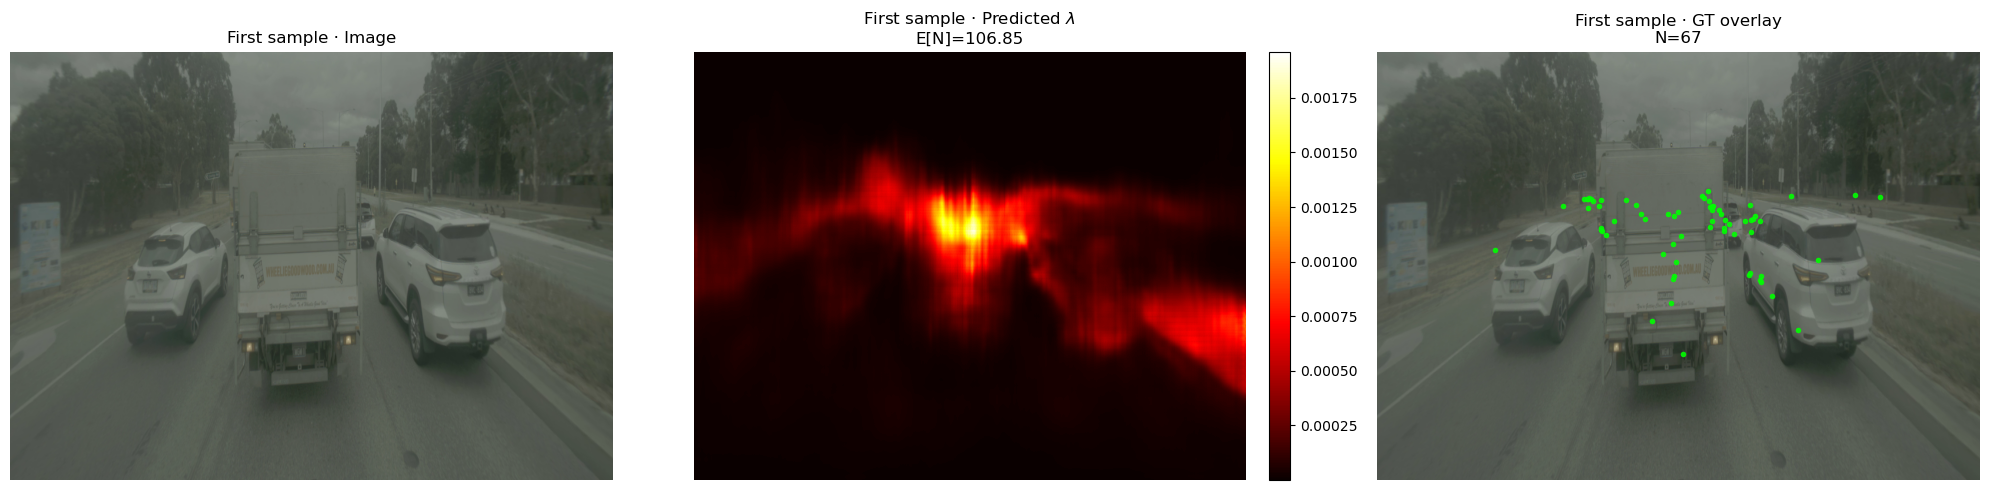

sigma=   0.000 | sigma_inc=   0.000 | time=0.0042s | sum_before_rescale=1.000000e+00 | score=  312.152743
sigma=   3.077 | sigma_inc=   3.077 | time=0.0414s | sum_before_rescale=9.984226e-01 | score=  311.740740
sigma=   6.154 | sigma_inc=   5.329 | time=0.0577s | sum_before_rescale=9.962552e-01 | score=  310.914923
sigma=   9.231 | sigma_inc=   6.880 | time=0.0555s | sum_before_rescale=9.939156e-01 | score=  309.834517
sigma=  12.308 | sigma_inc=   8.141 | time=0.0618s | sum_before_rescale=9.915090e-01 | score=  308.546058
sigma=  15.385 | sigma_inc=   9.231 | time=0.0857s | sum_before_rescale=9.890606e-01 | score=  307.066939
sigma=  18.462 | sigma_inc=  10.205 | time=0.0807s | sum_before_rescale=9.865738e-01 | score=  305.452471
sigma=  21.538 | sigma_inc=  11.094 | time=0.0835s | sum_before_rescale=9.840473e-01 | score=  303.763389
sigma=  24.615 | sigma_inc=  11.917 | time=0.0850s | sum_before_rescale=9.814788e-01 | score=  302.041978
sigma=  27.692 | sigma_inc=  12.686 | time=0.0

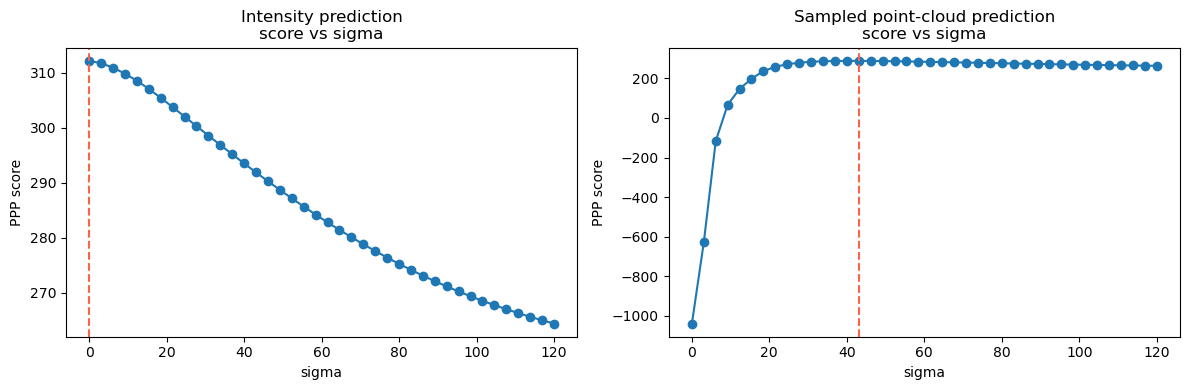

In [28]:
# ============================================================
# 7 · Quick Smoke Test on First Sample
# ============================================================

h5_path_0, key_0 = all_samples[0]
sample0 = load_h5_sample(h5_path_0, key_0)

img0 = sample0["img"]
pred_lambda0 = sample0["pred_lambda"]
gt_support0 = sample0["gt_support"]
ppp0 = sample0["ppp"]
meta0 = sample0["meta"]

print(f"Sample : {meta0['h5_file']} / {meta0['sample_key']}")
print(f"Shape  : {pred_lambda0.shape}")
print(f"E[N]   : {ppp0['expected_count']:.3f}")
print(f"GT N   : {ppp0['gt_count']}")

show_sample_triptych(img0, pred_lambda0, gt_support0, title_prefix="First sample · ")

res_int = optimize_sigma_for_grid(pred_lambda0, gt_support0, sigma_grid=SIGMA_GRID)
print("\nIntensity-based prediction")
print("Best sigma :", res_int["best_sigma"])
print("Best score :", res_int["best_score"])

sampled_pc0, sampled_meta0 = sample_point_cloud_from_lambda(
    pred_lambda0,
    rng=np.random.default_rng(0),
    mode=POINT_SAMPLING_MODE,
    gt_count=ppp0["gt_count"],
)

res_pc = optimize_sigma_for_grid(sampled_pc0, gt_support0, sigma_grid=SIGMA_GRID)
print("\nPoint-cloud prediction (one sampled realization)")
print("Sampling meta :", sampled_meta0)
print("Best sigma    :", res_pc["best_sigma"])
print("Best score    :", res_pc["best_score"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(res_int["sigma_grid"], res_int["scores"], marker="o")
ax[0].axvline(res_int["best_sigma"], color="tomato", linestyle="--")
ax[0].set_title("Intensity prediction\nscore vs sigma")
ax[0].set_xlabel("sigma")
ax[0].set_ylabel("PPP score")

ax[1].plot(res_pc["sigma_grid"], res_pc["scores"], marker="o")
ax[1].axvline(res_pc["best_sigma"], color="tomato", linestyle="--")
ax[1].set_title("Sampled point-cloud prediction\nscore vs sigma")
ax[1].set_xlabel("sigma")
ax[1].set_ylabel("PPP score")

plt.tight_layout()
plt.show()

I.e. The two evaluation pipelines exhibit fundamentally different behavior because they operate on different representations of the same underlying predictive distribution. When the predicted intensity field is evaluated directly, it already provides a smooth and spatially coherent estimate of the underlying point process. In this case, Gaussian smoothing acts purely as a degradation mechanism: increasing the smoothing scale disperses mass away from the ground-truth locations, leading to a monotonic decrease in the log-likelihood score.

In contrast, when a point cloud is sampled from the same intensity via a Poisson process, the prediction becomes a sparse and noisy realization of the distribution. At small smoothing scales, this representation assigns negligible density to most ground-truth locations, resulting in very low likelihood values. Gaussianization therefore plays a fundamentally different role: it acts as a kernel density estimator that compensates for sampling sparsity and variance. As the smoothing scale increases, the reconstructed density becomes more stable and better aligned with the ground truth, until excessive smoothing again destroys spatial precision.

This leads to a crucial observation: the optimal smoothing scale is not an intrinsic property of the underlying distribution, but depends strongly on its representation. While the intensity-based prediction prefers minimal smoothing, the sampled point cloud requires substantial smoothing to recover a meaningful density estimate. Consequently, the proposed metric does not evaluate predictions in a representation-invariant manner, but rather measures the best achievable likelihood after optimal reconstruction of a continuous density from the given representation.

# Optimization based method

## Newton Optimization for $\sigma$

We want to maximize the score $S(\sigma)$.

First, we switch to log-scale and set
$$
u = \log \sigma.
$$

For a given $\sigma = e^u$, we compute
$$
h = K_\sigma * z,
$$
$$
dh = (\partial_\sigma K_\sigma) * z,
$$
and
$$
d2h = (\partial_{\sigma\sigma} K_\sigma) * z.
$$

From these quantities, we compute the first and second derivative of the score with respect to $u$.

## Derivatives of the Score

We define
$$
S(\sigma)
=
\sum_{p \in P^{\mathrm{GT}}} \log h_\sigma(p)
-
\sum_{p \in \Omega} h_\sigma(p),
\qquad
h_\sigma = K_\sigma * z.
$$

---

### First derivative

$$
\frac{d}{d\sigma} S(\sigma)
=
\sum_{p \in P^{\mathrm{GT}}}
\frac{((\partial_\sigma K_\sigma) * z)(p)}{h_\sigma(p)}
-
\sum_{p \in \Omega} ((\partial_\sigma K_\sigma) * z)(p)
$$

---

### Second derivative

$$
\frac{d^2}{d\sigma^2} S(\sigma)
=
\sum_{p \in P^{\mathrm{GT}}}
\left[
\frac{((\partial_{\sigma\sigma} K_\sigma) * z)(p)}{h_\sigma(p)}
-
\frac{((\partial_\sigma K_\sigma) * z)(p)^2}{h_\sigma(p)^2}
\right]
-
\sum_{p \in \Omega} ((\partial_{\sigma\sigma} K_\sigma) * z)(p)
$$

---

### Kernel derivatives

$$
\partial_\sigma K_\sigma(r)
=
K_\sigma(r)\left(
-\frac{2}{\sigma}
+
\frac{\|r\|^2}{\sigma^3}
\right)
$$

$$
\partial_{\sigma\sigma} K_\sigma(r)
=
K_\sigma(r)\left(
\frac{6}{\sigma^2}
-
\frac{6\|r\|^2}{\sigma^4}
+
\frac{\|r\|^4}{\sigma^6}
\right)
$$


## Derivatives in Log-Scale

We define
$$
u = \log \sigma, \qquad \sigma = e^u.
$$

The score is
$$
S(\sigma)
=
\sum_{p \in P^{\mathrm{GT}}} \log h_\sigma(p)
-
\sum_{p \in \Omega} h_\sigma(p),
\qquad
h_\sigma = K_\sigma * z.
$$

---

### First derivative (log-scale, what we actually use in the algo)

Using the chain rule:
$$
\frac{d}{du} S(e^u)
=
\sigma \frac{d}{d\sigma} S(\sigma).
$$

So:
$$
g_u
=
\sigma
\left[
\sum_{p \in P^{\mathrm{GT}}}
\frac{((\partial_\sigma K_\sigma) * z)(p)}{h_\sigma(p)}
-
\sum_{p \in \Omega} ((\partial_\sigma K_\sigma) * z)(p)
\right]
$$

---

### Second derivative (log-scale, what we actually use in the algo)

$$
\frac{d^2}{du^2} S(e^u)
=
\sigma^2 \frac{d^2}{d\sigma^2} S(\sigma)
+
\sigma \frac{d}{d\sigma} S(\sigma).
$$

So:
$$
h_u
=
\sigma^2
\left[
\sum_{p \in P^{\mathrm{GT}}}
\left(
\frac{((\partial_{\sigma\sigma} K_\sigma) * z)(p)}{h_\sigma(p)}
-
\frac{((\partial_\sigma K_\sigma) * z)(p)^2}{h_\sigma(p)^2}
\right)
-
\sum_{p \in \Omega} ((\partial_{\sigma\sigma} K_\sigma) * z)(p)
\right]
+
\sigma g_\sigma
$$

where
$$
g_\sigma = \frac{d}{d\sigma} S(\sigma).
$$


## Why optimize in log-scale?

- Ensures sigma stays positive automatically  
- Turns multiplicative changes into additive steps  
- Makes the optimization stable across different scales  
- Prevents very large or very small update steps  
- Matches the natural scaling behavior of the Gaussian kernel  
- Improves numerical stability of derivative computations  
- Simplifies the optimization by removing constraints  

## Why is this allowed?

- It is just a change of variables (sigma ↔ log sigma)  
- The optimum does not change under this transformation  
- We can always convert back to sigma after optimization  

---

### Newton update

We then perform a Newton update:
$$
u_{k+1} = u_k - \frac{g_u}{h_u}.
$$

Or in log terms

$$
u_{k+1}
=
u_k - \frac{g_u}{h_u}.
$$

Finally,
$$
\sigma^* = e^{u^*}.
$$


To make the method stable, we use safeguards. We restrict the step size, keep $u$ inside a fixed interval, and reduce the step if the score decreases.

The algorithm stops when the gradient is small or when the update becomes very small.

Finally, we return the optimal value
$$
\sigma^* = e^{u^*}.
$$

In [11]:
import time
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.signal import fftconvolve


EPS_LOG = 1e-12


# ============================================================
# 1) Basic PPP score helpers
# ============================================================

def ppp_loglik_score(h, gt_support, eps=EPS_LOG):
    h = np.asarray(h, dtype=np.float64)
    gt_idx = np.asarray(gt_support) > 0
    return float(np.log(np.clip(h[gt_idx], eps, None)).sum() - h.sum())


def prepare_grid(grid):
    x = np.asarray(grid, dtype=np.float64)
    return np.clip(x, 0.0, None)


# ============================================================
# 2) Coarse search using Gaussian group property
# ============================================================

def optimize_sigma_for_grid(
    grid,
    gt_support,
    sigma_grid,
    verbose=False,
    truncate=4.0,
):
    """
    Approximate coarse sigma search using Gaussian variance additivity.

    IMPORTANT:
    - Incremental blurring uses the Gaussian semigroup / group property.
    - Before each PPP score evaluation, the blurred grid is rescaled
      back to the original total mass.
    - This keeps the PPP loss definition intact while still exploiting
      the group property approximately.

    This is still an approximation to evaluating scipy's gaussian_filter
    from scratch at each sigma, because of repeated truncation/boundary effects.
    """
    sigma_grid = np.asarray(sigma_grid, dtype=np.float64)

    if sigma_grid.ndim != 1 or len(sigma_grid) == 0:
        raise ValueError("sigma_grid must be a nonempty 1D array")
    if np.any(sigma_grid < 0):
        raise ValueError("sigma_grid must be nonnegative")
    if np.any(np.diff(sigma_grid) <= 0):
        raise ValueError("sigma_grid must be strictly increasing")

    x = prepare_grid(grid)
    gt_support = np.asarray(gt_support)

    if x.shape != gt_support.shape:
        raise ValueError("grid and gt_support must have the same shape")

    mass = x.sum()
    if mass <= 0:
        scores = np.full(len(sigma_grid), -np.inf, dtype=np.float64)
        return {
            "sigma_grid": sigma_grid,
            "scores": scores,
            "best_sigma": float(sigma_grid[0]),
            "best_score": float(scores[0]),
            "best_idx": 0,
        }

    gt_idx = gt_support > 0

    h_work = x / mass
    prev_sigma2 = 0.0
    scores = []

    for sigma in sigma_grid:
        sigma = float(sigma)
        sigma2 = sigma * sigma
        sigma_inc = math.sqrt(max(0.0, sigma2 - prev_sigma2))

        st = time.process_time()

        if sigma_inc > 0.0:
            h_work = gaussian_filter(
                h_work,
                sigma=sigma_inc,
                mode="constant",
                cval=0.0,
                truncate=truncate,
            )

        h_score = h_work.copy()
        s = h_score.sum()
        if s > 0:
            h_score *= mass / s
        else:
            h_score = np.zeros_like(h_score, dtype=np.float64)

        score = float(np.log(np.clip(h_score[gt_idx], EPS_LOG, None)).sum() - h_score.sum())
        scores.append(score)

        if verbose:
            print(
                f"sigma={sigma:8.3f} | sigma_inc={sigma_inc:8.3f} | "
                f"time={time.process_time() - st:.4f}s | "
                f"sum_before_rescale={s:.6e} | score={score:12.6f}"
            )

        prev_sigma2 = sigma2

    scores = np.asarray(scores, dtype=np.float64)
    best_idx = int(np.argmax(scores))

    return {
        "sigma_grid": sigma_grid,
        "scores": scores,
        "best_sigma": float(sigma_grid[best_idx]),
        "best_score": float(scores[best_idx]),
        "best_idx": best_idx,
    }


# ============================================================
# 3) Exact first derivative wrt sigma
# ============================================================

def gaussian_kernel_and_first_derivative(sigma, shape):
    sigma = float(sigma)
    if sigma <= 0:
        raise ValueError("sigma must be > 0")

    H, W = shape
    cy, cx = H // 2, W // 2

    yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")
    dy = yy - cy
    dx = xx - cx
    r2 = dx**2 + dy**2

    K = (1.0 / (2.0 * np.pi * sigma**2)) * np.exp(-r2 / (2.0 * sigma**2))
    dK = K * (-2.0 / sigma + r2 / sigma**3)

    return K, dK


def eval_score_grad_sigma(grid, gt_support, sigma, eps_h=EPS_LOG):
    """
    Exact score and exact first derivative wrt sigma.
    """
    z = np.asarray(grid, dtype=np.float64)
    gt_idx = np.asarray(gt_support) > 0

    K, dK = gaussian_kernel_and_first_derivative(sigma, z.shape)

    h = fftconvolve(z, K, mode="same")
    dh = fftconvolve(z, dK, mode="same")

    h_safe = np.maximum(h, eps_h)

    score = np.log(h_safe[gt_idx]).sum() - h.sum()
    grad = (dh[gt_idx] / h_safe[gt_idx]).sum() - dh.sum()

    return float(score), float(grad)


# ============================================================
# 4) Coarse interval selection
# ============================================================

def get_selected_interval_from_best_idx(sigma_grid, best_idx):
    sigma_grid = np.asarray(sigma_grid, dtype=np.float64)
    n = len(sigma_grid)

    if n < 2:
        raise ValueError("Need at least 2 grid points")

    if best_idx <= 0:
        return None

    if best_idx >= n - 1:
        return (
            float(sigma_grid[n - 2]),
            float(sigma_grid[n - 1]),
            float(sigma_grid[n - 1]),
        )

    return (
        float(sigma_grid[best_idx - 1]),
        float(sigma_grid[best_idx]),
        float(sigma_grid[best_idx + 1]),
    )


def quadratic_peak(s1, s2, s3, f1, f2, f3):
    denom = (s1 - s2) * (s1 - s3) * (s2 - s3)
    if abs(denom) < 1e-12:
        return float(s2)

    A = (s3 * (f2 - f1) + s2 * (f1 - f3) + s1 * (f3 - f2)) / denom
    B = (s3**2 * (f1 - f2) + s2**2 * (f3 - f1) + s1**2 * (f2 - f3)) / denom

    if abs(A) < 1e-12:
        return float(s2)

    return float(-B / (2.0 * A))


# ============================================================
# 5) Refinement with first derivative only
#    CRUCIAL: immediate RETURN once improvement <= loss_tol
# ============================================================

def refine_sigma_with_first_derivative(
    grid,
    gt_support,
    sigma_left,
    sigma_right,
    sigma_init=None,
    loss_tol=1e-2,
    max_iter=50,
    eps_h=EPS_LOG,
    verbose=False,
):
    if sigma_left <= 0:
        sigma_left = 1e-6
    if sigma_right <= sigma_left:
        raise ValueError("Need sigma_right > sigma_left")
    if loss_tol < 0:
        raise ValueError("loss_tol must be >= 0")

    left = float(sigma_left)
    right = float(sigma_right)

    if sigma_init is None:
        sigma = 0.5 * (left + right)
    else:
        sigma = float(np.clip(sigma_init, left, right))

    sigma_hist = []
    score_hist = []
    grad_hist = []
    left_hist = []
    right_hist = []
    improvement_hist = []

    best_sigma = None
    best_score = -np.inf
    prev_score = None

    for k in range(max_iter):
        score, grad = eval_score_grad_sigma(grid, gt_support, sigma, eps_h=eps_h)

        if prev_score is None:
            improvement = np.inf
        else:
            improvement = score - prev_score

        sigma_hist.append(float(sigma))
        score_hist.append(float(score))
        grad_hist.append(float(grad))
        left_hist.append(float(left))
        right_hist.append(float(right))
        improvement_hist.append(float(improvement))

        if score > best_score:
            best_score = float(score)
            best_sigma = float(sigma)

        if verbose:
            if np.isfinite(improvement):
                print(
                    f"iter={k:02d}  sigma={sigma:9.5f}  "
                    f"score={score:12.6f}  g={grad:12.6f}  impr={improvement:12.6f}"
                )
            else:
                print(
                    f"iter={k:02d}  sigma={sigma:9.5f}  "
                    f"score={score:12.6f}  g={grad:12.6f}  impr=         inf"
                )

        # IMMEDIATE STOP: print STOP and return right now
        if prev_score is not None and improvement <= loss_tol:
            if verbose:
                print(f"STOP: improvement {improvement:.6f} <= loss_tol {loss_tol:.6f}")
            return {
                "best_sigma": float(best_sigma),
                "best_score": float(best_score),
                "sigma_history": np.asarray(sigma_hist, dtype=np.float64),
                "score_history": np.asarray(score_hist, dtype=np.float64),
                "grad_history": np.asarray(grad_hist, dtype=np.float64),
                "left_history": np.asarray(left_hist, dtype=np.float64),
                "right_history": np.asarray(right_hist, dtype=np.float64),
                "improvement_history": np.asarray(improvement_hist, dtype=np.float64),
                "sigma_left_init": float(sigma_left),
                "sigma_right_init": float(sigma_right),
                "sigma_init": float(np.clip(
                    sigma_init if sigma_init is not None else 0.5 * (sigma_left + sigma_right),
                    sigma_left,
                    sigma_right
                )),
                "status": "loss_tol_stop",
                "loss_tol": float(loss_tol),
            }

        if grad > 0:
            left = sigma
        elif grad < 0:
            right = sigma
        else:
            if verbose:
                print("STOP: gradient exactly zero")
            return {
                "best_sigma": float(best_sigma),
                "best_score": float(best_score),
                "sigma_history": np.asarray(sigma_hist, dtype=np.float64),
                "score_history": np.asarray(score_hist, dtype=np.float64),
                "grad_history": np.asarray(grad_hist, dtype=np.float64),
                "left_history": np.asarray(left_hist, dtype=np.float64),
                "right_history": np.asarray(right_hist, dtype=np.float64),
                "improvement_history": np.asarray(improvement_hist, dtype=np.float64),
                "sigma_left_init": float(sigma_left),
                "sigma_right_init": float(sigma_right),
                "sigma_init": float(np.clip(
                    sigma_init if sigma_init is not None else 0.5 * (sigma_left + sigma_right),
                    sigma_left,
                    sigma_right
                )),
                "status": "grad_zero_stop",
                "loss_tol": float(loss_tol),
            }

        sigma_new = 0.5 * (left + right)

        if abs(sigma_new - sigma) < 1e-12:
            if verbose:
                print("STOP: interval collapsed")
            return {
                "best_sigma": float(best_sigma),
                "best_score": float(best_score),
                "sigma_history": np.asarray(sigma_hist, dtype=np.float64),
                "score_history": np.asarray(score_hist, dtype=np.float64),
                "grad_history": np.asarray(grad_hist, dtype=np.float64),
                "left_history": np.asarray(left_hist, dtype=np.float64),
                "right_history": np.asarray(right_hist, dtype=np.float64),
                "improvement_history": np.asarray(improvement_hist, dtype=np.float64),
                "sigma_left_init": float(sigma_left),
                "sigma_right_init": float(sigma_right),
                "sigma_init": float(np.clip(
                    sigma_init if sigma_init is not None else 0.5 * (sigma_left + sigma_right),
                    sigma_left,
                    sigma_right
                )),
                "status": "interval_collapsed_stop",
                "loss_tol": float(loss_tol),
            }

        prev_score = score
        sigma = sigma_new

    if verbose:
        print("STOP: max_iter reached")

    return {
        "best_sigma": float(best_sigma),
        "best_score": float(best_score),
        "sigma_history": np.asarray(sigma_hist, dtype=np.float64),
        "score_history": np.asarray(score_hist, dtype=np.float64),
        "grad_history": np.asarray(grad_hist, dtype=np.float64),
        "left_history": np.asarray(left_hist, dtype=np.float64),
        "right_history": np.asarray(right_hist, dtype=np.float64),
        "improvement_history": np.asarray(improvement_hist, dtype=np.float64),
        "sigma_left_init": float(sigma_left),
        "sigma_right_init": float(sigma_right),
        "sigma_init": float(np.clip(
            sigma_init if sigma_init is not None else 0.5 * (sigma_left + sigma_right),
            sigma_left,
            sigma_right
        )),
        "status": "max_iter_stop",
        "loss_tol": float(loss_tol),
    }


# ============================================================
# 6) Full hybrid algorithm
# ============================================================

def optimize_sigma_hybrid_group_then_grad(
    grid,
    gt_support,
    sigma_max=120.0,
    n_coarse=21,
    loss_tol=1e-2,
    truncate=4.0,
    refine_max_iter=50,
    verbose=False,
):
    if sigma_max <= 0:
        raise ValueError("sigma_max must be > 0")
    if n_coarse < 3:
        raise ValueError("n_coarse must be >= 3")
    if loss_tol < 0:
        raise ValueError("loss_tol must be >= 0")

    sigma_grid = np.linspace(0.0, sigma_max, n_coarse)

    coarse_res = optimize_sigma_for_grid(
        grid=grid,
        gt_support=gt_support,
        sigma_grid=sigma_grid,
        verbose=verbose,
        truncate=truncate,
    )

    best_idx = coarse_res["best_idx"]
    best_sigma_coarse = float(coarse_res["best_sigma"])
    best_score_coarse = float(coarse_res["best_score"])

    zero_boundary_selected = (best_idx == 0)
    selected_interval = get_selected_interval_from_best_idx(coarse_res["sigma_grid"], best_idx)

    best_sigma = best_sigma_coarse
    best_score = best_score_coarse
    refinement = None
    status = "zero_boundary_selected" if zero_boundary_selected else "coarse_only"

    if (not zero_boundary_selected) and (selected_interval is not None):
        s1, s2, s3 = selected_interval

        score_lookup = {
            float(s): float(sc)
            for s, sc in zip(coarse_res["sigma_grid"], coarse_res["scores"])
        }

        f1 = score_lookup[float(s1)]
        f2 = score_lookup[float(s2)]
        f3 = score_lookup[float(s3)]

        sigma_init = quadratic_peak(s1, s2, s3, f1, f2, f3)
        sigma_init = float(np.clip(sigma_init, max(s1, 1e-6), s3))

        if verbose:
            print("\nSelected intervals:")
            print(f"  [{s1:.6f}, {s3:.6f}] with center {s2:.6f}")
            print(
                f"\nRefinement 1: interval=[{s1:.6f}, {s3:.6f}], "
                f"quad_init={sigma_init:.6f}"
            )

        refinement = refine_sigma_with_first_derivative(
            grid=grid,
            gt_support=gt_support,
            sigma_left=s1,
            sigma_right=s3,
            sigma_init=sigma_init,
            loss_tol=loss_tol,
            max_iter=refine_max_iter,
            eps_h=EPS_LOG,
            verbose=verbose,
        )

        if refinement["best_score"] > best_score:
            best_score = float(refinement["best_score"])
            best_sigma = float(refinement["best_sigma"])
            status = "refined_with_first_derivative"
        else:
            status = "coarse_better_than_refinement"

    return {
        "best_sigma": float(best_sigma),
        "best_score": float(best_score),
        "status": status,
        "zero_boundary_selected": bool(zero_boundary_selected),
        "loss_tol": float(loss_tol),
        "coarse": coarse_res,
        "selected_interval": selected_interval,
        "refinement": refinement,
    }

In [12]:
# ===========================================================
# 7) Plotting
# ============================================================

def plot_sigma_hybrid_result(res, title="Sigma optimization"):
    coarse = res["coarse"]
    sigma_grid = np.asarray(coarse["sigma_grid"], dtype=np.float64)
    coarse_scores = np.asarray(coarse["scores"], dtype=np.float64)

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    ax0 = ax[0]
    ax0.plot(
        sigma_grid,
        coarse_scores,
        marker="o",
        linewidth=2,
        markersize=6,
        label="coarse score (group property)"
    )

    interval = res.get("selected_interval", None)
    if interval is not None:
        s1, s2, s3 = interval
        ax0.axvspan(s1, s3, alpha=0.18, label="selected interval")
        ax0.axvline(s2, linestyle=":", linewidth=1.5, color="gray", label="coarse center")

    ax0.axvline(
        coarse["best_sigma"],
        linestyle="--",
        linewidth=2,
        color="tab:orange",
        label="best coarse"
    )

    ax0.axvline(
        res["best_sigma"],
        linestyle="-.",
        linewidth=2,
        color="black",
        label="final best"
    )

    msg = "0-boundary selected" if res["zero_boundary_selected"] else "0-boundary not selected"
    ax0.text(
        0.02, 0.98, msg,
        transform=ax0.transAxes,
        va="top", ha="left",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.7")
    )

    ax0.set_xlabel("sigma")
    ax0.set_ylabel("score")
    ax0.set_title(f"{title} — coarse search")
    ax0.grid(True, alpha=0.25)
    ax0.legend()

    ax1 = ax[1]
    refinement = res.get("refinement", None)

    if refinement is None:
        reason = "0-boundary selected in coarse search"
        ax1.text(
            0.5, 0.5,
            f"No derivative refinement\n({reason})",
            ha="center", va="center", fontsize=12,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9, edgecolor="0.7"),
            transform=ax1.transAxes
        )
        ax1.axvline(
            res["best_sigma"],
            linestyle="--",
            linewidth=2,
            color="black",
            label="final best"
        )
        ax1.set_xlabel("sigma")
        ax1.set_ylabel("score")
        ax1.set_title(f"{title} — derivative refinement")
        ax1.grid(True, alpha=0.25)
        ax1.legend()
    else:
        sigma_hist = refinement["sigma_history"]
        score_hist = refinement["score_history"]
        left_hist = refinement["left_history"]
        right_hist = refinement["right_history"]

        ax1.plot(
            sigma_hist,
            score_hist,
            marker="o",
            linewidth=2,
            markersize=5,
            label="refinement path"
        )

        for i in range(len(left_hist)):
            ax1.axvspan(
                left_hist[i],
                right_hist[i],
                alpha=0.08,
                color="gray",
                label="active bracket" if i == 0 else None
            )

        if len(score_hist) > 0:
            ax1.scatter(
                [refinement["sigma_init"]],
                [score_hist[0]],
                marker="s",
                s=80,
                zorder=5,
                label="initial refinement point"
            )

        ax1.axvline(
            res["best_sigma"],
            linestyle="--",
            linewidth=2,
            color="black",
            label="final best"
        )

        ax1.set_xlabel("sigma")
        ax1.set_ylabel("score")
        ax1.set_title(f"{title} — derivative refinement")
        ax1.grid(True, alpha=0.25)
        ax1.legend()

    fig.suptitle(
        f"{title}\n"
        f"best sigma = {res['best_sigma']:.6f}, best score = {res['best_score']:.6f}, "
        f"status = {res['status']}, loss_tol = {res['loss_tol']:.3e}",
        fontsize=12
    )
    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()


def plot_sigma_hybrid_comparison(res_left, res_right, title_left="Intensity", title_right="Point cloud"):
    fig, ax = plt.subplots(2, 2, figsize=(15, 10))

    for col, (res, title) in enumerate([(res_left, title_left), (res_right, title_right)]):
        coarse = res["coarse"]
        sigma_grid = np.asarray(coarse["sigma_grid"], dtype=np.float64)
        coarse_scores = np.asarray(coarse["scores"], dtype=np.float64)
        interval = res.get("selected_interval", None)
        refinement = res.get("refinement", None)

        a0 = ax[0, col]
        a0.plot(
            sigma_grid,
            coarse_scores,
            marker="o",
            linewidth=2,
            markersize=6,
            label="coarse score (group property)"
        )

        if interval is not None:
            s1, s2, s3 = interval
            a0.axvspan(s1, s3, alpha=0.18, label="selected interval")
            a0.axvline(s2, linestyle=":", linewidth=1.5, color="gray", label="coarse center")

        a0.axvline(
            coarse["best_sigma"],
            linestyle="--",
            linewidth=2,
            color="tab:orange",
            label="best coarse"
        )
        a0.axvline(
            res["best_sigma"],
            linestyle="-.",
            linewidth=2,
            color="black",
            label="final best"
        )

        a0.text(
            0.02, 0.98,
            "0-boundary selected" if res["zero_boundary_selected"] else "0-boundary not selected",
            transform=a0.transAxes,
            va="top", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.7")
        )

        a0.set_title(f"{title} — coarse search")
        a0.set_xlabel("sigma")
        a0.set_ylabel("score")
        a0.grid(True, alpha=0.25)
        a0.legend()

        a1 = ax[1, col]
        if refinement is None:
            a1.text(
                0.5, 0.5,
                "No derivative refinement\n(0-boundary selected in coarse search)",
                ha="center", va="center", fontsize=11,
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.9, edgecolor="0.7"),
                transform=a1.transAxes
            )
            a1.axvline(
                res["best_sigma"],
                linestyle="--",
                linewidth=2,
                color="black",
                label="final best"
            )
            a1.set_title(f"{title} — derivative refinement")
            a1.set_xlabel("sigma")
            a1.set_ylabel("score")
            a1.grid(True, alpha=0.25)
            a1.legend()
        else:
            sigma_hist = refinement["sigma_history"]
            score_hist = refinement["score_history"]
            left_hist = refinement["left_history"]
            right_hist = refinement["right_history"]

            a1.plot(
                sigma_hist,
                score_hist,
                marker="o",
                linewidth=2,
                markersize=5,
                label="refinement path"
            )

            for i in range(len(left_hist)):
                a1.axvspan(
                    left_hist[i],
                    right_hist[i],
                    alpha=0.08,
                    color="gray",
                    label="active bracket" if i == 0 else None
                )

            if len(score_hist) > 0:
                a1.scatter(
                    [refinement["sigma_init"]],
                    [score_hist[0]],
                    marker="s",
                    s=80,
                    zorder=5,
                    label="initial refinement point"
                )

            a1.axvline(
                res["best_sigma"],
                linestyle="--",
                linewidth=2,
                color="black",
                label="final best"
            )

            a1.set_title(f"{title} — derivative refinement")
            a1.set_xlabel("sigma")
            a1.set_ylabel("score")
            a1.grid(True, alpha=0.25)
            a1.legend()

    fig.suptitle(
        f"Sigma optimization comparison (loss_tol = {res_left['loss_tol']:.3e})",
        fontsize=14
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

sigma=   0.000 | sigma_inc=   0.000 | time=0.0089s | sum_before_rescale=1.000000e+00 | score= -611.779726
sigma=  30.000 | sigma_inc=  30.000 | time=0.2835s | sum_before_rescale=9.851428e-01 | score= -625.480102
sigma=  60.000 | sigma_inc=  51.962 | time=0.5399s | sum_before_rescale=9.630545e-01 | score= -641.472456
sigma=  90.000 | sigma_inc=  67.082 | time=0.6661s | sum_before_rescale=9.280146e-01 | score= -653.862450
sigma= 120.000 | sigma_inc=  79.373 | time=0.7507s | sum_before_rescale=8.714816e-01 | score= -662.666640


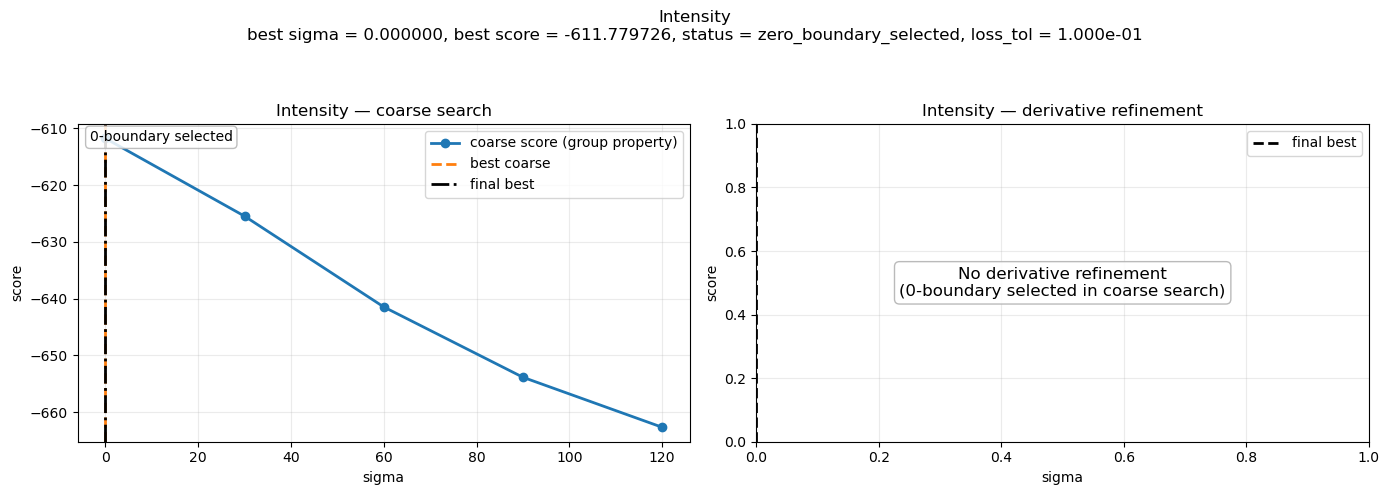

sigma=   0.000 | sigma_inc=   0.000 | time=0.0102s | sum_before_rescale=1.000000e+00 | score=-1962.278415
sigma=  30.000 | sigma_inc=  30.000 | time=0.2825s | sum_before_rescale=9.849612e-01 | score= -641.687960
sigma=  60.000 | sigma_inc=  51.962 | time=0.4653s | sum_before_rescale=9.640012e-01 | score= -641.022214
sigma=  90.000 | sigma_inc=  67.082 | time=0.6533s | sum_before_rescale=9.316948e-01 | score= -653.101792
sigma= 120.000 | sigma_inc=  79.373 | time=0.7323s | sum_before_rescale=8.773310e-01 | score= -663.422259

Selected intervals:
  [30.000000, 90.000000] with center 60.000000

Refinement 1: interval=[30.000000, 90.000000], quad_init=46.567036
iter=00  sigma= 46.56704  score= -635.734101  g=   -0.203444  impr=         inf
iter=01  sigma= 38.28352  score= -635.340049  g=    0.171802  impr=    0.394052
iter=02  sigma= 42.42528  score= -635.157182  g=   -0.063206  impr=    0.182867
iter=03  sigma= 40.35440  score= -635.127660  g=    0.039100  impr=    0.029522
STOP: improvem

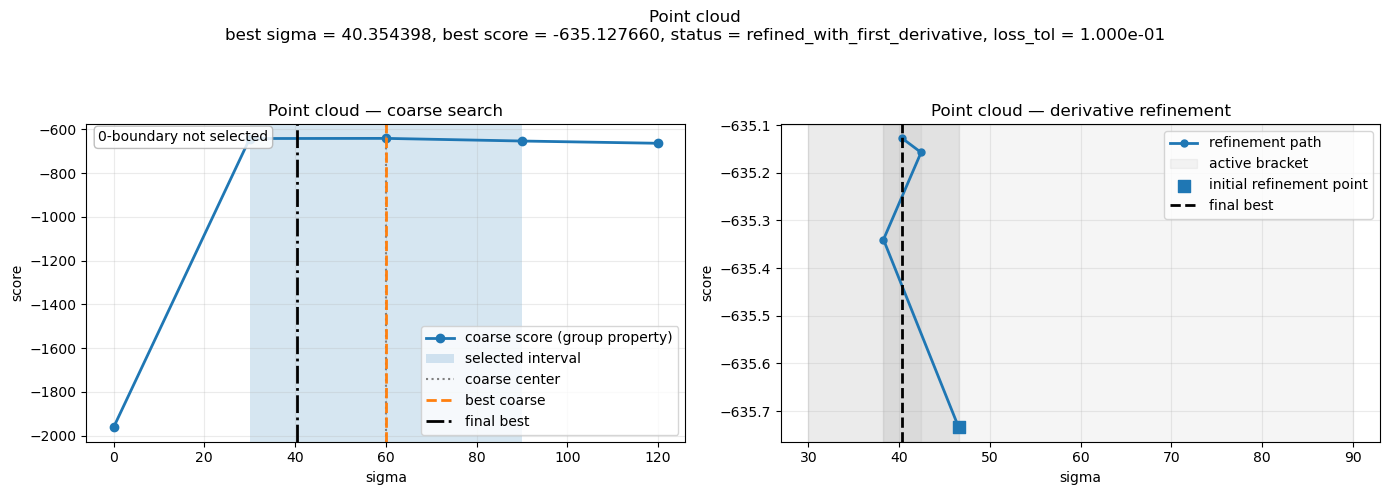

In [13]:
# ============================================================
# 8) Example usage
# ============================================================

res_int = optimize_sigma_hybrid_group_then_grad(
    pred_lambda0,
    gt_support0,
    sigma_max=120.0,
    n_coarse=5,
    loss_tol=1e-1,
    verbose=True,
)
plot_sigma_hybrid_result(res_int, title="Intensity")

res_pc = optimize_sigma_hybrid_group_then_grad(
    sampled_pc0,
    gt_support0,
    sigma_max=120.0,
    n_coarse=5,
    loss_tol=1e-1,
    verbose=True,
)
plot_sigma_hybrid_result(res_pc, title="Point cloud")

## Ternary Search for Optimal Gaussian Scale

We optimize the Gaussian smoothing parameter $\sigma$ by maximizing the PPP log-likelihood after Gaussianization. Since the score as a function of $\sigma$ is typically **unimodal** (increasing for small $\sigma$, decreasing for large $\sigma$), we can apply **ternary search**.

### Objective

Let
\[
S(\sigma)
\]
denote the PPP log-likelihood after Gaussianizing the grid with scale $\sigma$. We aim to solve:
\[
\sigma^* = \arg\max_{\sigma \in [\sigma_{\min}, \sigma_{\max}]} S(\sigma).
\]

---

### Algorithm

At each iteration, we maintain an interval $[l, r]$ and evaluate two interior points:
\[
m_1 = l + \frac{r - l}{3}, \qquad
m_2 = r - \frac{r - l}{3}.
\]

We compare the scores:
- If $S(m_1) < S(m_2)$, the maximum lies in $[m_1, r]$ → discard $[l, m_1]$.
- Otherwise, the maximum lies in $[l, m_2]$ → discard $[m_2, r]$.

This reduces the interval length by a factor of $\tfrac{2}{3}$ each iteration.

---

### Stopping Criterion

The procedure terminates when:
\[
r - l < \varepsilon,
\]
and the optimal value is approximated by:
\[
\sigma^* \approx \frac{l + r}{2}.
\]

---

### Practical Considerations

- The score function $S(\sigma)$ is evaluated via Gaussian convolution and PPP log-likelihood.
- To reduce computation, previously evaluated $\sigma$ values are cached.
- The special case $\sigma = 0$ is evaluated separately, as it corresponds to no smoothing.
- Boundary points are checked at the end to avoid missing edge optima.

In [ ]:
# ============================================================
# Ternary search for sigma (unified)
# Assumes the score is roughly unimodal on [sigma_min, sigma_max].
# ============================================================

def score_sigma_zero(grid, gt_support, eps_h=1e-12): 
    h = grid.astype(np.float64) 
    gt_idx = gt_support > 0 
    h_safe = np.maximum(h, eps_h) 
    return np.log(h_safe[gt_idx]).sum() - h.sum()

def optimize_sigma_ternary_for_grid(
    grid,
    gt_support,
    sigma_min=0.0,
    sigma_max=100.0,
    max_iter=30,
    tol_sigma=0.5,
    eps_h=1e-12,
    check_zero=True,
    verbose=False,
):
    if sigma_max <= sigma_min:
        raise ValueError("Need sigma_max > sigma_min")
    if sigma_min < 0:
        raise ValueError("sigma_min must be >= 0")

    x = prepare_grid(grid)
    if x.sum() <= 0:
        return {
            "best_sigma": float(sigma_min),
            "best_score": -np.inf,
            "sigma_history": np.asarray([], dtype=np.float64),
            "score_history": np.asarray([], dtype=np.float64),
            "status": "empty_grid",
        }

    eval_cache = {}

    def eval_sigma(s):
        s = float(max(0.0, s))
        key = round(s, 12)
        if key in eval_cache:
            return eval_cache[key]

        if s == 0.0:
            score = score_sigma_zero(x, gt_support, eps_h=eps_h)
        else:
            h = gaussianize_grid(x, s)
            score = ppp_loglik_score(h, gt_support, eps=eps_h)

        eval_cache[key] = float(score)
        return eval_cache[key]

    sigma_hist = []
    score_hist = []

    best_sigma = None
    best_score = -np.inf

    if check_zero and sigma_min == 0.0:
        score0 = eval_sigma(0.0)
        best_sigma = 0.0
        best_score = score0
        sigma_hist.append(0.0)
        score_hist.append(score0)

    left = math.log(max(sigma_min, 0.1))
    right = math.log(max(sigma_max, 0.1))
    for k in range(max_iter):
        if (right - left) < tol_sigma: # logarithmic tolerance
            break

        m1 = left + (right - left) / 3.0
        m2 = right - (right - left) / 3.0

        s1 = eval_sigma(math.exp(m1))
        s2 = eval_sigma(math.exp(m2))

        sigma_hist.extend([math.exp(m1), math.exp(m2)])
        score_hist.extend([s1, s2])

        if s1 > best_score:
            best_score = s1
            best_sigma = math.exp(m1)
        if s2 > best_score:
            best_score = s2
            best_sigma = math.exp(m2)

        if verbose:
            print(
                f"iter={k:02d}  left={math.exp(left):8.3f}  m1={math.exp(m1):8.3f}  m2={math.exp(m2):8.3f}  right={math.exp(right):8.3f}  "
                f"s1={s1:12.6f}  s2={s2:12.6f}"
            )

        # Keep the side containing the larger value.
        if s1 < s2:
            left = m1
        else:
            right = m2

    sigma_mid = 0.5 * (left + right)
    score_mid = eval_sigma(math.exp(sigma_mid))
    sigma_hist.append(math.exp(sigma_mid))
    score_hist.append(score_mid)

    if score_mid > best_score:
        best_score = score_mid
        best_sigma = sigma_mid

    # Also check interval boundaries at the end.
    if False: # not neeeded because left and right are already evaluated except if they are the initial boundaries, but we have the midpoint evaluated
        score_left = eval_sigma(left)
        score_right = eval_sigma(right)

        sigma_hist.extend([left, right])
        score_hist.extend([score_left, score_right])

        if score_left > best_score:
            best_score = score_left
            best_sigma = left
        if score_right > best_score:
            best_score = score_right
            best_sigma = right

    return {
        "best_sigma": float(best_sigma),
        "best_score": float(best_score),
        "sigma_history": np.asarray(sigma_hist, dtype=np.float64),
        "score_history": np.asarray(score_hist, dtype=np.float64),
        "status": "ok",
        "interval_final": (float(left), float(right)),
    }

def gaussianize_grid(grid, sigma): # Apply Gaussian blur while approximately preserving total mass. 
    x = prepare_grid(grid) 
    mass = x.sum() 
    
    if mass <= 0: 
        return np.zeros_like(x, dtype=np.float64) 
    
    if float(sigma) == 0.0: 
        return x.copy() 
    
    y = gaussian_filter(x / mass, sigma=float(sigma), mode="constant", cval=0.0) 
    s = y.sum() 
    if s > 0: 
        y *= mass / s 
    
    return y
    

In [24]:
def plot_sigma_curve_ternary(res, title="Ternary search\nscore along optimization"):
    fig, ax = plt.subplots(1, 1, figsize=(6, 4))

    ax.plot(res["sigma_history"], res["score_history"], marker="o")
    ax.axvline(res["best_sigma"], color="tomato", linestyle="--", label=f"best σ = {res['best_sigma']:.3f}")

    ax.set_title(title)
    ax.set_xlabel("sigma")
    ax.set_ylabel("PPP score")
    ax.legend()

    plt.tight_layout()
    plt.show()

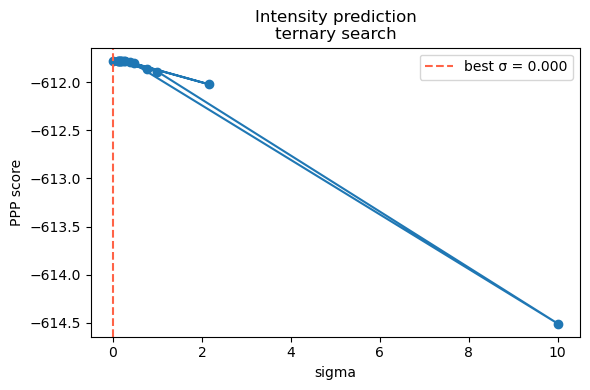

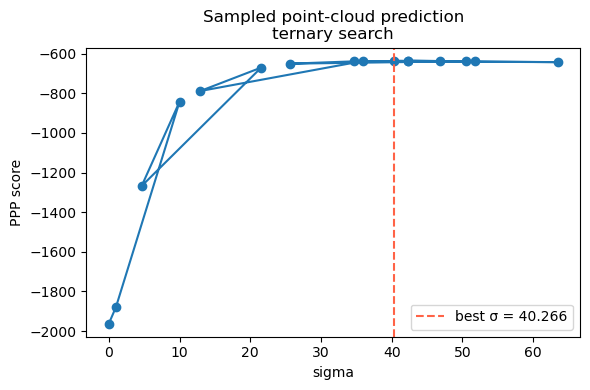

In [25]:
res_int = optimize_sigma_ternary_for_grid(pred_lambda0, gt_support0)
plot_sigma_curve_ternary(res_int, title="Intensity prediction\nternary search")
res_pc = optimize_sigma_ternary_for_grid(sampled_pc0, gt_support0)
plot_sigma_curve_ternary(res_pc, title="Sampled point-cloud prediction\nternary search")

# Golden-Search

In [26]:
import math
import numpy as np


def optimize_sigma_golden_for_grid(
    grid,
    gt_support,
    sigma_min=0.0,
    sigma_max=100.0,
    max_iter=30,
    tol_sigma=0.5,
    eps_h=1e-12,
    check_zero=True,
    verbose=False,
):
    if sigma_max <= sigma_min:
        raise ValueError("Need sigma_max > sigma_min")
    if sigma_min < 0:
        raise ValueError("sigma_min must be >= 0")

    x = prepare_grid(grid)
    if x.sum() <= 0:
        return {
            "best_sigma": float(sigma_min),
            "best_score": -np.inf,
            "sigma_history": np.asarray([], dtype=np.float64),
            "score_history": np.asarray([], dtype=np.float64),
            "status": "empty_grid",
        }

    eval_cache = {}

    def eval_sigma(s):
        s = float(max(0.0, s))
        key = round(s, 12)
        if key in eval_cache:
            return eval_cache[key]

        if s == 0.0:
            score = score_sigma_zero(x, gt_support, eps_h=eps_h)
        else:
            h = gaussianize_grid(x, s)
            score = ppp_loglik_score(h, gt_support, eps=eps_h)

        eval_cache[key] = float(score)
        return eval_cache[key]

    sigma_hist = []
    score_hist = []

    best_sigma = None
    best_score = -np.inf

    if check_zero and sigma_min == 0.0:
        score0 = eval_sigma(0.0)
        best_sigma = 0.0
        best_score = score0
        sigma_hist.append(0.0)
        score_hist.append(score0)

    # Work in log-space, but avoid log(0).
    log_left = math.log(max(sigma_min, 0.1))
    log_right = math.log(max(sigma_max, 0.1))

    phi = (1.0 + math.sqrt(5.0)) / 2.0
    inv_phi = 1.0 / phi

    # Initial interior points
    c = log_right - (log_right - log_left) * inv_phi
    d = log_left + (log_right - log_left) * inv_phi

    sc = eval_sigma(math.exp(c))
    sd = eval_sigma(math.exp(d))

    sigma_hist.extend([math.exp(c), math.exp(d)])
    score_hist.extend([sc, sd])

    if sc > best_score:
        best_score = sc
        best_sigma = math.exp(c)
    if sd > best_score:
        best_score = sd
        best_sigma = math.exp(d)

    for k in range(max_iter):
        # true sigma-width stopping criterion
        if (math.exp(log_right) - math.exp(log_left)) < tol_sigma:
            break

        if verbose:
            print(
                f"iter={k:02d}  "
                f"left={math.exp(log_left):8.3f}  "
                f"c={math.exp(c):8.3f}  "
                f"d={math.exp(d):8.3f}  "
                f"right={math.exp(log_right):8.3f}  "
                f"sc={sc:12.6f}  sd={sd:12.6f}"
            )

        if sc < sd:
            # Keep [c, right]
            log_left = c
            c = d
            sc = sd
            d = log_left + (log_right - log_left) * inv_phi
            sd = eval_sigma(math.exp(d))

            sigma_hist.append(math.exp(d))
            score_hist.append(sd)

            if sd > best_score:
                best_score = sd
                best_sigma = math.exp(d)
        else:
            # Keep [left, d]
            log_right = d
            d = c
            sd = sc
            c = log_right - (log_right - log_left) * inv_phi
            sc = eval_sigma(math.exp(c))

            sigma_hist.append(math.exp(c))
            score_hist.append(sc)

            if sc > best_score:
                best_score = sc
                best_sigma = math.exp(c)

    sigma_mid = math.exp(0.5 * (log_left + log_right))
    score_mid = eval_sigma(sigma_mid)

    sigma_hist.append(sigma_mid)
    score_hist.append(score_mid)

    if score_mid > best_score:
        best_score = score_mid
        best_sigma = sigma_mid

    return {
        "best_sigma": float(best_sigma),
        "best_score": float(best_score),
        "sigma_history": np.asarray(sigma_hist, dtype=np.float64),
        "score_history": np.asarray(score_hist, dtype=np.float64),
        "status": "ok",
        "interval_final": (float(math.exp(log_left)), float(math.exp(log_right))),
    }

In [27]:
def plot_sigma_curve(res, title="Sigma search\nscore along optimization"):
    fig, ax = plt.subplots(1, 1, figsize=(6, 4))

    ax.plot(res["sigma_history"], res["score_history"], marker="o")
    ax.axvline(
        res["best_sigma"],
        color="tomato",
        linestyle="--",
        label=f"best σ = {res['best_sigma']:.3f}",
    )

    ax.set_title(title)
    ax.set_xlabel("sigma")
    ax.set_ylabel("PPP score")
    ax.legend()

    plt.tight_layout()
    plt.show()

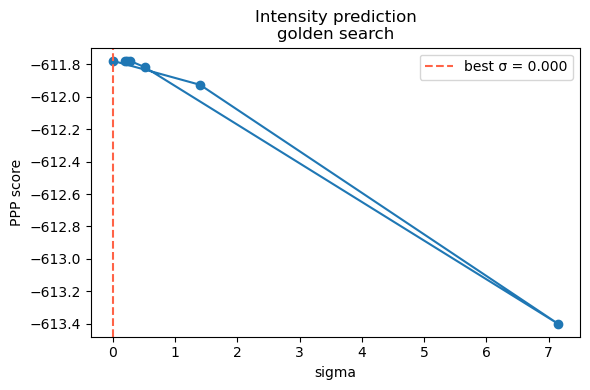

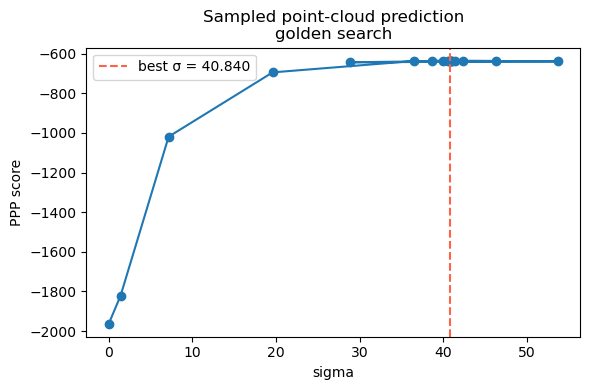

In [28]:
res_int = optimize_sigma_golden_for_grid(pred_lambda0, gt_support0)
plot_sigma_curve(res_int, title="Intensity prediction\ngolden search")

res_pc = optimize_sigma_golden_for_grid(sampled_pc0, gt_support0)
plot_sigma_curve(res_pc, title="Sampled point-cloud prediction\ngolden search")

# 8 — Interactive single-image browser

In [29]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from scipy.ndimage import binary_dilation

GT_DILATION_RADIUS = 1


# ── persistent selection list ────────────────────────────────────────────────
selected_samples = []   # list of (h5_file, sample_key)

# ── widgets ──────────────────────────────────────────────────────────────────
n = len(all_samples)

slider = widgets.IntSlider(
    value=0, min=0, max=n - 1, step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="600px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆  Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

lbl_status = widgets.Label(value=f"0 / {n} selected")

plot_out   = widgets.Output()
select_out = widgets.Output()


def _update_btn_label(idx):
    """Reflect whether the current sample is already in the selection."""
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)
    btn_add.value       = entry in selected_samples
    btn_add.description = "★  In selection" if btn_add.value else "☆  Add to selection"
    btn_add.button_style = "success" if btn_add.value else ""


def _render(idx):
    h5_path, key = all_samples[idx]
    sample = load_h5_sample(h5_path, key)

    img         = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support  = sample["gt_support"]
    ppp         = sample["ppp"]
    meta        = sample["meta"]

    gt_ys, gt_xs = np.where(gt_support > 0)

    with plot_out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(22, 5))

        axes[0].imshow(img, aspect="auto")
        axes[0].set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
        axes[0].axis("off")

        im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
        axes[1].set_title(
            r"Predicted $\lambda(x)$" + f"\nE[N] = {ppp['expected_count']:.2f}",
            fontsize=10,
        )
        axes[1].axis("off")
        plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

        _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
        _gt_vis = binary_dilation(gt_support > 0, structure=_struct)
        _gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
        _gt_rgb[_gt_vis] = 255
        axes[2].imshow(_gt_rgb, aspect="auto")
        axes[2].set_title(
            f"GT support\nN = {ppp['gt_count']}",
            fontsize=10,
        )
        axes[2].axis("off")

        plt.suptitle(
            f"[{idx + 1}/{n}]  {meta['h5_file']}  ·  {meta['sample_key']}"
            f"   |   E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}"
            f"  err={ppp['count_error']:+.2f}",
            fontsize=11, y=1.02,
        )
        plt.tight_layout()
        plt.show()


def _refresh_selection_output():
    with select_out:
        clear_output(wait=True)
        if selected_samples:
            print(f"Selected ({len(selected_samples)}):")
            for h5f, k in selected_samples:
                print(f"  {h5f}  /  {k}")
        else:
            print("No samples selected yet.")


def on_slider_change(change):
    _update_btn_label(change["new"])
    _render(change["new"])


def on_toggle_change(change):
    idx = slider.value
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)

    if change["new"]:                          # toggled ON → add
        if entry not in selected_samples:
            selected_samples.append(entry)
        btn_add.description  = "★  In selection"
        btn_add.button_style = "success"
    else:                                      # toggled OFF → remove
        if entry in selected_samples:
            selected_samples.remove(entry)
        btn_add.description  = "☆  Add to selection"
        btn_add.button_style = ""

    lbl_status.value = f"{len(selected_samples)} / {n} selected"
    _refresh_selection_output()


slider.observe(on_slider_change, names="value")
btn_add.observe(on_toggle_change, names="value")

# ── initial render ────────────────────────────────────────────────────────────
_update_btn_label(0)
_render(0)
_refresh_selection_output()

# ── layout ────────────────────────────────────────────────────────────────────
controls = widgets.HBox([slider, btn_add, lbl_status])

display(widgets.VBox([controls, plot_out, select_out]))
# ── layout ────────────────────────────────────────────────────────────────────controls = widgets.HBox([slider, btn_add, lbl_status])display(widgets.VBox([controls, plot_out, select_out]))


In [ ]:
import os

def get_selected_indices(selected_samples, all_samples):
    indices = []

    for i, (h5_path, key) in enumerate(all_samples):
        entry = (os.path.basename(h5_path), key)
        if entry in selected_samples:
            indices.append(i)

    return indices

In [ ]:
selected_indices = get_selected_indices(selected_samples, all_samples)
print(selected_indices)

In [ ]:
# ============================================================
# 9 · Run sigma optimization on selected images
# ============================================================

method = "grid_naive"   # "grid", "minimize_sigma", "ternary", "golden", "grid_naive"
sample_seed = 0


def optimize_sigma_dispatch(grid, gt_support, method):
    print(method.upper(), "optimization for grid of shape", grid.shape)

    if method == "grid_naive":
        sigma_grid = np.linspace(0.0, 150.0, 60)
        return optimize_sigma_for_grid_naive(
            grid,
            gt_support,
            sigma_grid=sigma_grid,
            verbose=True,
        )
    
    if method == "grid":
        sigma_grid = np.linspace(0., 150.0, 60)
        return optimize_sigma_for_grid(
            grid,
            gt_support,
            sigma_grid=sigma_grid,
            verbose=True
        )

    if method == "minimize_sigma":
        return optimize_sigma_newton_robust_with_history(
            grid,
            gt_support,
            initial_checks=(0.0, 1.0, 50.0, 100.0, 150.0),
            verbose=True,
            sigma_min=0.0,
            sigma_max=150.0,
            max_iter=20,
            tol_g=1e-6,
            tol_sigma=5e-1,
            min_step=2.0,
            max_step=20.0,
            eps_h=1e-12,
        )

    if method == "ternary":
        return optimize_sigma_ternary_for_grid(
            grid,
            gt_support,
            sigma_min=0.0,
            sigma_max=150.0,
            max_iter=30,
            tol_sigma=0.01,  # logarithmic tolerance
            verbose=True,
        )

    if method == "golden":
        return optimize_sigma_golden_for_grid(
            grid,
            gt_support,
            sigma_min=0.0,
            sigma_max=150.0,
            max_iter=30,
            tol_sigma=0.5,   # now in sigma-space (important!)
            verbose=True,
        )

    raise ValueError(f"Unknown method: {method}")


def plot_sigma_curves(res_int, res_pc, method):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    if method == "grid":
        ax[0].plot(res_int["sigma_grid"], res_int["scores"], marker="o")
        ax[0].axvline(res_int["best_sigma"], color="tomato", linestyle="--")
        ax[0].set_title("Intensity prediction\nscore vs sigma")

        ax[1].plot(res_pc["sigma_grid"], res_pc["scores"], marker="o")
        ax[1].axvline(res_pc["best_sigma"], color="tomato", linestyle="--")
        ax[1].set_title("Sampled point-cloud prediction\nscore vs sigma")
    else:
        ax[0].plot(res_int["sigma_history"], res_int["score_history"], marker="o")
        ax[0].axvline(res_int["best_sigma"], color="tomato", linestyle="--")
        ax[0].set_title("Intensity prediction\nscore along optimization")

        ax[1].plot(res_pc["sigma_history"], res_pc["score_history"], marker="o")
        ax[1].axvline(res_pc["best_sigma"], color="tomato", linestyle="--")
        ax[1].set_title("Sampled point-cloud prediction\nscore along optimization")

    ax[0].set_xlabel("sigma")
    ax[0].set_ylabel("PPP score")
    ax[1].set_xlabel("sigma")
    ax[1].set_ylabel("PPP score")

    plt.tight_layout()
    plt.show()


def show_result_for_one_sample(idx, method="minimize_sigma", sample_seed=0):
    h5_path, key = all_samples[idx]
    s = load_h5_sample(h5_path, key)

    img = s["img"]
    pred_lambda = s["pred_lambda"]
    gt_support = s["gt_support"]
    ppp = s["ppp"]
    meta = s["meta"]

    sampled_pc, sampled_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(sample_seed),
        mode=POINT_SAMPLING_MODE,
        gt_count=ppp["gt_count"],
    )

    res_int = optimize_sigma_dispatch(pred_lambda, gt_support, method)
    res_pc = optimize_sigma_dispatch(sampled_pc, gt_support, method)

    sigma_int = float(res_int["best_sigma"])
    sigma_pc = float(res_pc["best_sigma"])

    g_int = gaussianize_grid(pred_lambda, sigma_int)
    g_pc = gaussianize_grid(sampled_pc, sigma_pc)

    gt_ys, gt_xs = np.where(gt_support > 0)
    pc_ys, pc_xs = np.where(sampled_pc > 0)

    print(f"Sample         : {meta['h5_file']} / {meta['sample_key']}")
    print(f"Index          : {idx}")
    print(f"E[N]           : {ppp['expected_count']:.3f}")
    print(f"GT count       : {ppp['gt_count']}")
    print(f"Point sample   : {sampled_meta}")
    print(f"Method         : {method}")
    print(f"Best intensity : score={res_int['best_score']:.6f}, sigma={sigma_int}")
    print(f"Best pointcloud: score={res_pc['best_score']:.6f}, sigma={sigma_pc}")

    fig, axes = plt.subplots(2, 4, figsize=(22, 10))

    # intensity branch
    axes[0, 0].imshow(img, aspect="auto")
    axes[0, 0].set_title("Image")
    axes[0, 0].axis("off")

    im0 = axes[0, 1].imshow(pred_lambda, cmap="hot", aspect="auto")
    axes[0, 1].set_title(r"Heatmap $\lambda$")
    axes[0, 1].axis("off")
    plt.colorbar(im0, ax=axes[0, 1], fraction=0.046, pad=0.04)

    axes[0, 2].imshow(img, aspect="auto")
    axes[0, 2].scatter(gt_xs, gt_ys, s=GT_DOT_SIZE, c="lime", linewidths=0)
    axes[0, 2].set_title(f"Ground truth\nN={int(gt_support.sum())}")
    axes[0, 2].axis("off")

    axes[0, 3].imshow(img, aspect="auto")
    im1 = axes[0, 3].imshow(g_int, cmap="hot", alpha=0.55, aspect="auto")
    axes[0, 3].scatter(gt_xs, gt_ys, s=GT_DOT_SIZE, c="cyan", linewidths=0)
    axes[0, 3].set_title(f"Gaussianized heatmap + GT\nσ={sigma_int:.3f}")
    axes[0, 3].axis("off")
    plt.colorbar(im1, ax=axes[0, 3], fraction=0.046, pad=0.04)

    # sample branch
    axes[1, 0].imshow(img, aspect="auto")
    axes[1, 0].set_title("Image")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(img, aspect="auto")
    axes[1, 1].scatter(pc_xs, pc_ys, s=GT_DOT_SIZE, c="deepskyblue", linewidths=0)
    axes[1, 1].set_title(f"Sample\nN={int(sampled_pc.sum())}")
    axes[1, 1].axis("off")

    axes[1, 2].imshow(img, aspect="auto")
    axes[1, 2].scatter(gt_xs, gt_ys, s=GT_DOT_SIZE, c="lime", linewidths=0)
    axes[1, 2].set_title(f"Ground truth\nN={int(gt_support.sum())}")
    axes[1, 2].axis("off")

    axes[1, 3].imshow(img, aspect="auto")
    im2 = axes[1, 3].imshow(g_pc, cmap="hot", alpha=0.55, aspect="auto")
    axes[1, 3].scatter(gt_xs, gt_ys, s=GT_DOT_SIZE, c="cyan", linewidths=0)
    axes[1, 3].set_title(f"Gaussianized sample + GT\nσ={sigma_pc:.3f}")
    axes[1, 3].axis("off")
    plt.colorbar(im2, ax=axes[1, 3], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

    plot_sigma_curves(res_int, res_pc, method)


if not selected_indices:
    print("No selected images. Use the selector cell first.")
else:
    print(f"Running on selected indices: {selected_indices}\n")
    for idx in selected_indices:
        show_result_for_one_sample(idx, method=method, sample_seed=sample_seed)
        print("\n" + "=" * 100 + "\n")
"""
Running on selected indices: [9]

TERNARY optimization for grid of shape (544, 1792)
iter=00  left=   0.000  m1=  50.000  m2= 100.000  right= 150.000  s1=-2060.016636  s2=-2028.293313
iter=01  left=  50.000  m1=  83.333  m2= 116.667  right= 150.000  s1=-2034.965977  s2=-2024.746929
iter=02  left=  83.333  m1= 105.556  m2= 127.778  right= 150.000  s1=-2026.821620  s2=-2023.583977
iter=03  left= 105.556  m1= 120.370  m2= 135.185  right= 150.000  s1=-2024.271093  s2=-2023.193147
iter=04  left= 120.370  m1= 130.247  m2= 140.123  right= 150.000  s1=-2023.423867  s2=-2023.068143
iter=05  left= 130.247  m1= 136.831  m2= 143.416  right= 150.000  s1=-2023.140518  s2=-2023.036038
iter=06  left= 136.831  m1= 141.221  m2= 145.610  right= 150.000  s1=-2023.053153  s2=-2023.035075
iter=07  left= 141.221  m1= 144.147  m2= 147.074  right= 150.000  s1=-2023.033968  s2=-2023.042780
iter=08  left= 141.221  m1= 143.172  m2= 145.123  right= 147.074  s1=-2023.037123  s2=-2023.033966
iter=09  left= 143.172  m1= 144.472  m2= 145.773  right= 147.074  s1=-2023.033627  s2=-2023.035593
iter=10  left= 143.172  m1= 144.039  m2= 144.906  right= 145.773  s1=-2023.034189  s2=-2023.033673
iter=11  left= 144.039  m1= 144.617  m2= 145.195  right= 145.773  s1=-2023.033605  s2=-2023.034051
iter=12  left= 144.039  m1= 144.424  m2= 144.810  right= 145.195  s1=-2023.033649  s2=-2023.033636
iter=13  left= 144.424  m1= 144.681  m2= 144.938  right= 145.195  s1=-2023.033572  s2=-2023.033707
iter=14  left= 144.424  m1= 144.595  m2= 144.767  right= 144.938  s1=-2023.033604  s2=-2023.033609
TERNARY optimization for grid of shape (544, 1792)
iter=00  left=   0.000  m1=  50.000  m2= 100.000  right= 150.000  s1=-2013.959359  s2=-1985.281916
iter=01  left=  50.000  m1=  83.333  m2= 116.667  right= 150.000  s1=-1991.743599  s2=-1982.427848
iter=02  left=  83.333  m1= 105.556  m2= 127.778  right= 150.000  s1=-1983.976132  s2=-1982.031755
iter=03  left= 105.556  m1= 120.370  m2= 135.185  right= 150.000  s1=-1982.182969  s2=-1982.262695
iter=04  left= 105.556  m1= 115.432  m2= 125.309  right= 135.185  s1=-1982.537234  s2=-1982.035941
iter=05  left= 115.432  m1= 122.016  m2= 128.601  right= 135.185  s1=-1982.112135  s2=-1982.039906
...
Point sample   : {'mode': 'thinning', 'num_points': 167, 'grid_count_sum': 167, 'binary_count': 167, 'lambda_max': 0.0007978230132721364, 'n_proposals': 789, 'expected_count_input': 141.80141649829784}
Method         : ternary
Best intensity : score=-2023.033572, sigma=144.6811279772041
Best pointcloud: score=-1982.028065, sigma=126.81615749548033

Grid:

Sigma vs score:
  sigma=   0.000  score=-2075.979092
  sigma=   2.542  score=-2075.571414
  sigma=   5.085  score=-2075.208680
  sigma=   7.627  score=-2074.841231
  sigma=  10.169  score=-2074.397137
  sigma=  12.712  score=-2073.855484
  sigma=  15.254  score=-2073.216144
  sigma=  17.797  score=-2072.468414
  sigma=  20.339  score=-2071.585510
  sigma=  22.881  score=-2070.530208
  sigma=  25.424  score=-2069.263209
  sigma=  27.966  score=-2067.749820
  sigma=  30.508  score=-2065.966615
  sigma=  33.051  score=-2063.903743
  sigma=  35.593  score=-2061.565009
  sigma=  38.136  score=-2058.965871
  sigma=  40.678  score=-2056.130857
  sigma=  43.220  score=-2053.091704
  sigma=  45.763  score=-2049.883832
  sigma=  48.305  score=-2046.546031
  sigma=  50.847  score=-2043.118316
  sigma=  53.390  score=-2039.640748
  sigma=  55.932  score=-2036.150630
  sigma=  58.475  score=-2032.683150
  sigma=  61.017  score=-2029.268816
  sigma=  63.559  score=-2025.934628
  sigma=  66.102  score=-2022.702352
  sigma=  68.644  score=-2019.590011
  sigma=  71.186  score=-2016.611126
  sigma=  73.729  score=-2013.775166
  sigma=  76.271  score=-2011.088748
  sigma=  78.814  score=-2008.555343
  sigma=  81.356  score=-2006.175818
  sigma=  83.898  score=-2003.949334
  sigma=  86.441  score=-2001.873273
  sigma=  88.983  score=-1999.943727
  sigma=  91.525  score=-1998.155752
  sigma=  94.068  score=-1996.503795
  sigma=  96.610  score=-1994.981755
  sigma=  99.153  score=-1993.583201
  sigma= 101.695  score=-1992.301525
  sigma= 104.237  score=-1991.130100
  sigma= 106.780  score=-1990.062257
  sigma= 109.322  score=-1989.091489
  sigma= 111.864  score=-1988.211437
  sigma= 114.407  score=-1987.415940
  sigma= 116.949  score=-1986.699058
  sigma= 119.492  score=-1986.055089
  sigma= 122.034  score=-1985.478577
  sigma= 124.576  score=-1984.964315
  sigma= 127.119  score=-1984.507343
  sigma= 129.661  score=-1984.102943
  sigma= 132.203  score=-1983.746629
  sigma= 134.746  score=-1983.434144
  sigma= 137.288  score=-1983.161449
  sigma= 139.831  score=-1982.924715
  sigma= 142.373  score=-1982.720313
  sigma= 144.915  score=-1982.544806
  sigma= 147.458  score=-1982.394946
  sigma= 150.000  score=-1982.267663
"""

# Loss distribution

Is the loss comparable over a set of images?

In [ ]:
# ============================================================
# 10 · Loss distribution over a random subset of images
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


def compute_loss_for_sample(idx, method="minimize_sigma", sample_seed=0, use_sample=False):
    h5_path, key = all_samples[idx]
    s = load_h5_sample(h5_path, key)

    pred_lambda = s["pred_lambda"]
    gt_support = s["gt_support"]
    ppp = s["ppp"]

    if use_sample:
        grid, sampled_meta = sample_point_cloud_from_lambda(
            pred_lambda,
            rng=np.random.default_rng(sample_seed + idx),
            mode=POINT_SAMPLING_MODE,
            gt_count=ppp["gt_count"],
        )
    else:
        grid = pred_lambda

    if method == "grid":
        res = optimize_sigma_for_grid(grid, gt_support, sigma_grid=SIGMA_GRID, verbose=False)
    elif method == "minimize_sigma":
        res = optimize_sigma_newton_robust_with_history(
            grid,
            gt_support,
            initial_checks=(0.0, 1.0, 50.0, 100.0),
            verbose=False,
            sigma_min=0.0,
            sigma_max=100.0,
            max_iter=20,
            tol_g=1e-6,
            tol_sigma=5e-1,
            min_step=2.0,
            max_step=20.0,
            eps_h=1e-12,
)
    elif method == "ternary":
        res = optimize_sigma_ternary_for_grid(
            grid,
            gt_support,
            sigma_min=0.0,
            sigma_max=100.0,
            max_iter=30,
            tol_sigma=0.5,
            verbose=False,
        )
    else:
        raise ValueError(f"Unknown method: {method}")

    # We define loss as negative best score.
    loss = -float(res["best_score"])

    return {
        "idx": idx,
        "loss": loss,
        "best_sigma": float(res["best_sigma"]),
        "best_score": float(res["best_score"]),
    }


def evaluate_loss_distribution(
    n_images,
    method="minimize_sigma",
    random_seed=0,
    sample_seed=0,
    use_sample=False,
    replace=False,
    bins=20,
    verbose=True,
):
    n_total = len(all_samples)
    if n_images <= 0:
        raise ValueError("n_images must be > 0")
    if not replace and n_images > n_total:
        raise ValueError("n_images cannot exceed dataset size when replace=False")

    rng = np.random.default_rng(random_seed)
    indices = rng.choice(n_total, size=n_images, replace=replace)
    indices = [int(i) for i in indices]

    results = []
    losses = []

    for k, idx in enumerate(indices, 1):
        out = compute_loss_for_sample(
            idx,
            method=method,
            sample_seed=sample_seed,
            use_sample=use_sample,
        )
        results.append(out)
        losses.append(out["loss"])

        if verbose:
            print(
                f"[{k:>3}/{n_images}] idx={idx:>5}  "
                f"loss={out['loss']:.6f}  sigma={out['best_sigma']:.4f}"
            )

    losses = np.asarray(losses, dtype=np.float64)

    mean_loss = float(losses.mean())
    var_loss = float(losses.var())
    std_loss = float(losses.std())

    plt.figure(figsize=(8, 5))
    plt.hist(losses, bins=bins)
    plt.axvline(mean_loss, linestyle="--", label=f"mean = {mean_loss:.4f}")
    plt.title(
        f"Loss distribution ({'sample' if use_sample else 'intensity'})\n"
        f"method={method}, n={n_images}"
    )
    plt.xlabel("loss = - best_score")
    plt.ylabel("count")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Mean     : {mean_loss:.6f}")
    print(f"Variance : {var_loss:.6f}")
    print(f"Std      : {std_loss:.6f}")

    return {
        "indices": indices,
        "results": results,
        "losses": losses,
        "mean_loss": mean_loss,
        "var_loss": var_loss,
        "std_loss": std_loss,
        "method": method,
        "use_sample": use_sample,
    }

In [ ]:
dist_int = evaluate_loss_distribution(
    n_images=50,
    method="minimize_sigma",
    random_seed=1,
    use_sample=False,
    bins=20
)